Ensemble Learning: Bagging with Decision Trees

In [ ]:


import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns # data visualization library
import matplotlib.pyplot as plt
import time
from subprocess import check_output

#import warnings library
import warnings
# ignore all warnings
warnings.filterwarnings('ignore')


<a id='3'></a>
## Read and Analyse Data

In [ ]:
data = pd.read_csv('data.csv')

In [ ]:
data.head()  # head method show only first 5 rows

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [ ]:
# feature names as a list
col = data.columns       # .columns gives columns names in data
print(col)

Index(['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean',
       'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'concavity_worst', 'concave points_worst',
       'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32'],
      dtype='object')


What this cell does: separates the label from the features.

y = the label (diagnosis: M or B)
x = all feature columns, after dropping id, diagnosis and the empty Unnamed: 32
errors='ignore' stops it failing if Unnamed: 32 is not present in your copy of the file.

In [ ]:

y = data.diagnosis
list = ['Unnamed: 32','id','diagnosis']
x = data.drop(list,axis = 1 )
x.head()

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


What this cell does: plots and counts the classes (Benign vs Malignant). Checking class balance matters because it tells us whether plain accuracy is a fair metric. Here the data is moderately balanced (357 B / 212 M).

Number of Benign:  357
Number of Malignant :  212


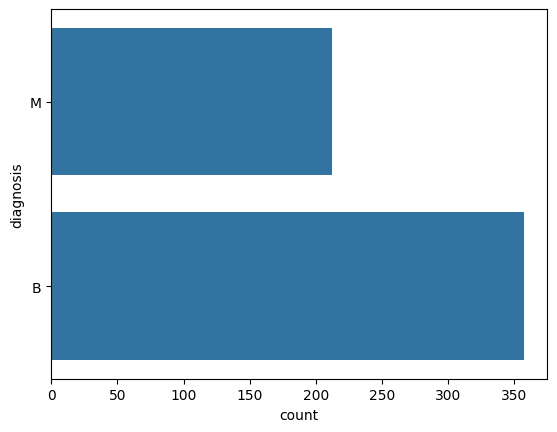

In [ ]:
ax = sns.countplot(y,label="Count")       # M = 212, B = 357
B, M = y.value_counts()
print('Number of Benign: ',B)
print('Number of Malignant : ',M)

What this cell does: describe() gives count, mean, std, min and max for every feature. Notice the very different scales (for example area_mean goes up to about 2500 while smoothness_mean is below 0.2). Decision trees do not need scaling because they split on thresholds, so we do not standardise before modelling.

In [ ]:
x.describe()

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


3. Visualization
What this cell does: draws a violin plot of the first 10 features, split by diagnosis. We standardise the values only for this plot so all features fit on one axis. If the Malignant and Benign shapes are clearly separated for a feature (e.g. texture_mean), it is useful for classification. If they overlap (e.g. fractal_dimension_mean), it is less useful.

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
 [Text(0, 0, 'radius_mean'),
  Text(1, 0, 'texture_mean'),
  Text(2, 0, 'perimeter_mean'),
  Text(3, 0, 'area_mean'),
  Text(4, 0, 'smoothness_mean'),
  Text(5, 0, 'compactness_mean'),
  Text(6, 0, 'concavity_mean'),
  Text(7, 0, 'concave points_mean'),
  Text(8, 0, 'symmetry_mean'),
  Text(9, 0, 'fractal_dimension_mean')])

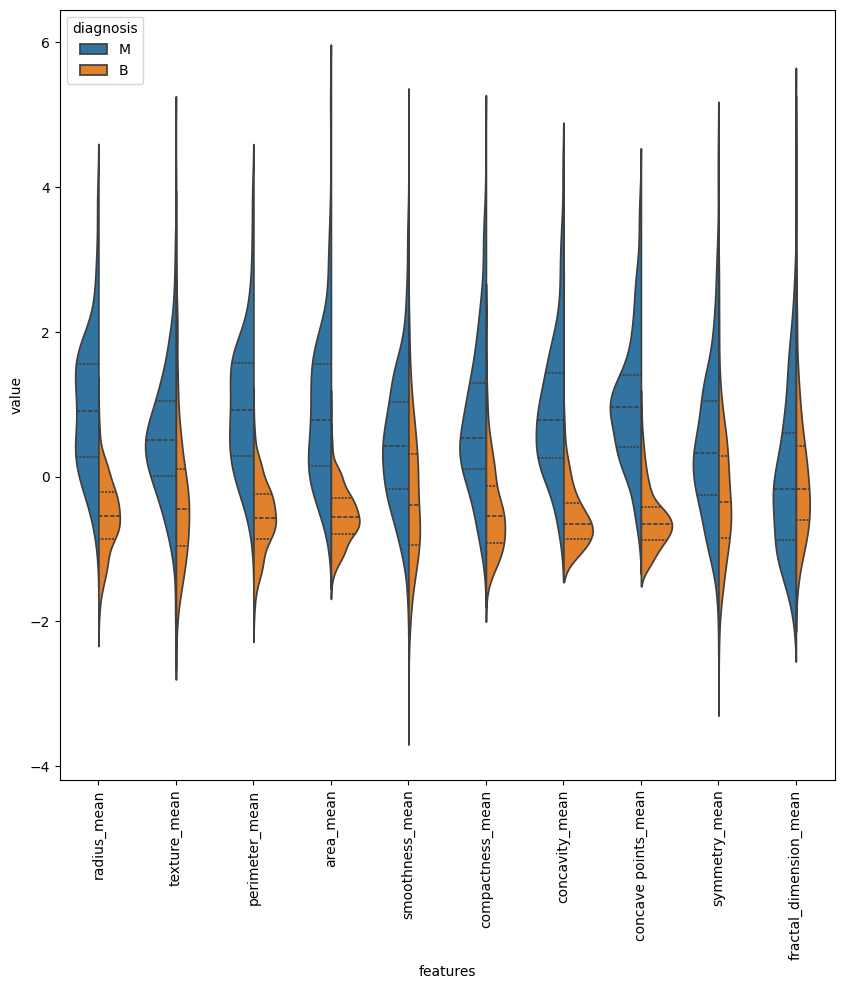

In [ ]:
# first ten features
data_dia = y
data = x
data_n_2 = (data - data.mean()) / (data.std())              # standardization
data = pd.concat([y,data_n_2.iloc[:,0:10]],axis=1)
data = pd.melt(data,id_vars="diagnosis",
                    var_name="features",
                    value_name='value')
plt.figure(figsize=(10,10))
sns.violinplot(x="features", y="value", hue="diagnosis", data=data,split=True, inner="quart")
plt.xticks(rotation=90)

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
 [Text(0, 0, 'radius_mean'),
  Text(1, 0, 'texture_mean'),
  Text(2, 0, 'perimeter_mean'),
  Text(3, 0, 'area_mean'),
  Text(4, 0, 'smoothness_mean'),
  Text(5, 0, 'compactness_mean'),
  Text(6, 0, 'concavity_mean'),
  Text(7, 0, 'concave points_mean'),
  Text(8, 0, 'symmetry_mean'),
  Text(9, 0, 'fractal_dimension_mean')])

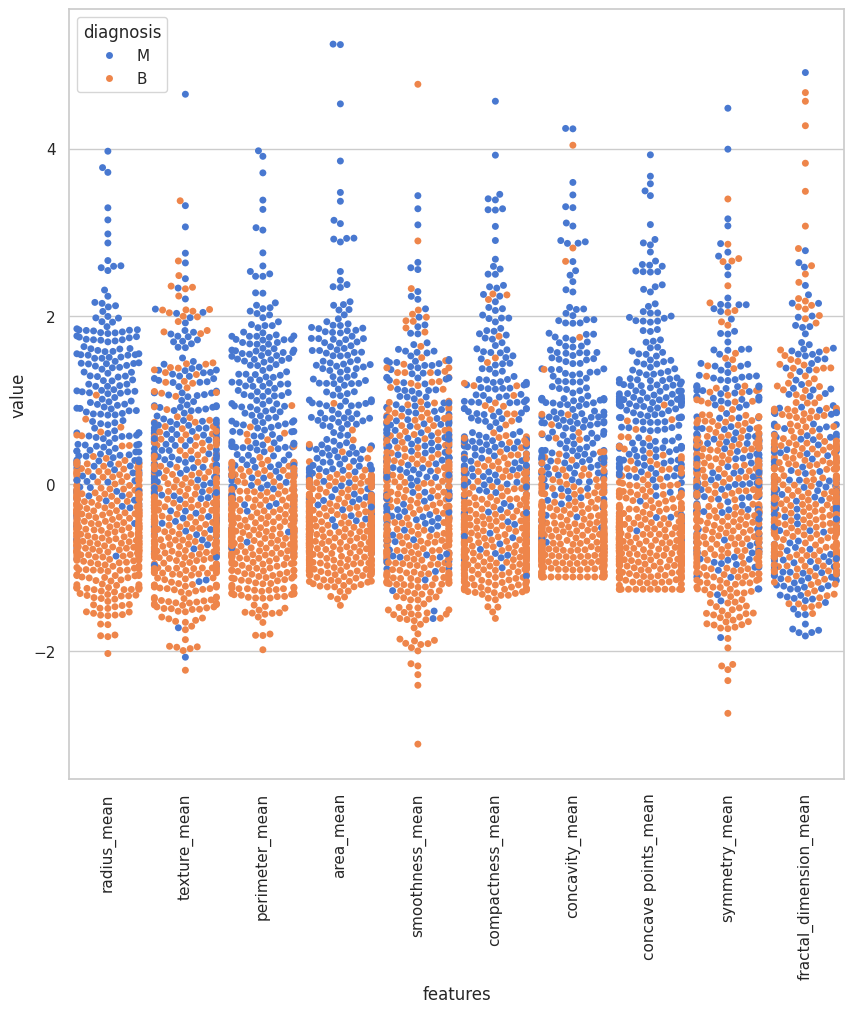

In [ ]:
sns.set(style="whitegrid", palette="muted")
data_dia = y
data = x
data_n_2 = (data - data.mean()) / (data.std())              # standardization
data = pd.concat([y,data_n_2.iloc[:,0:10]],axis=1)
data = pd.melt(data,id_vars="diagnosis",
                    var_name="features",
                    value_name='value')
plt.figure(figsize=(10,10))
tic = time.time()
sns.swarmplot(x="features", y="value", hue="diagnosis", data=data)

plt.xticks(rotation=90)

<Axes: >

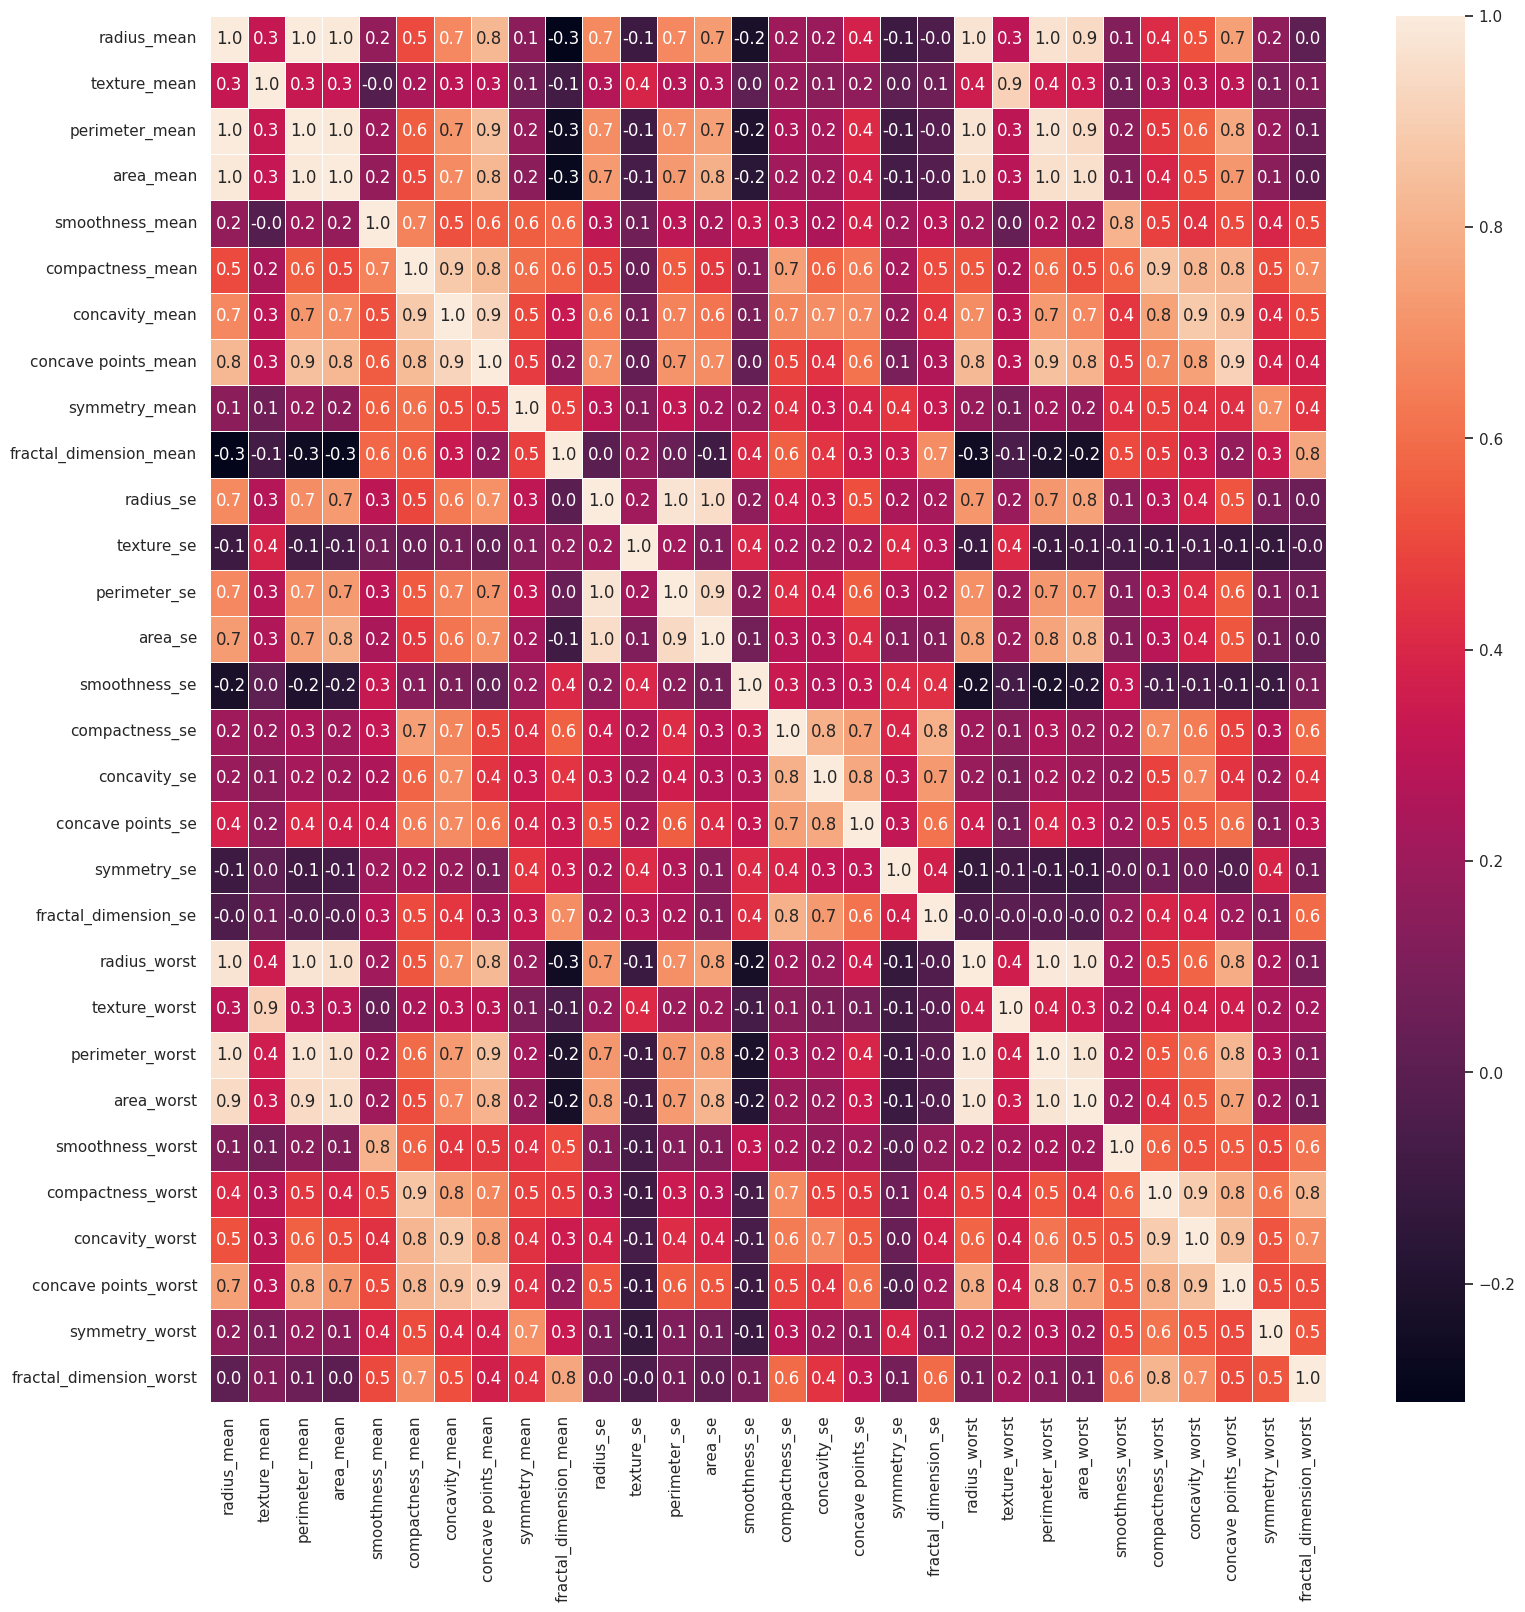

In [ ]:
#correlation map
f,ax = plt.subplots(figsize=(18, 18))
sns.heatmap(x.corr(), annot=True, linewidths=.5, fmt= '.1f',ax=ax)

In [ ]:
drop_list1 = ['perimeter_mean','radius_mean','compactness_mean','concave points_mean','radius_se','perimeter_se','radius_worst','perimeter_worst','compactness_worst','concave points_worst','compactness_se','concave points_se','texture_worst','area_worst']
x_1 = x.drop(drop_list1,axis = 1 )        # do not modify x, we will use it later
x_1.head()



,texture_mean,area_mean,smoothness_mean,concavity_mean,symmetry_mean,fractal_dimension_mean,texture_se,area_se,smoothness_se,concavity_se,symmetry_se,fractal_dimension_se,smoothness_worst,concavity_worst,symmetry_worst,fractal_dimension_worst
0,10.38,1001.0,0.11840,0.3001,0.2419,0.07871,0.9053,153.40,0.006399,0.05373,0.03003,0.006193,0.1622,0.7119,0.4601,0.11890
1,17.77,1326.0,0.08474,0.0869,0.1812,0.05667,0.7339,74.08,0.005225,0.01860,0.01389,0.003532,0.1238,0.2416,0.2750,0.08902
2,21.25,1203.0,0.10960,0.1974,0.2069,0.05999,0.7869,94.03,0.006150,0.03832,0.02250,0.004571,0.1444,0.4504,0.3613,0.08758
3,20.38,386.1,0.14250,0.2414,0.2597,0.09744,1.1560,27.23,0.009110,0.05661,0.05963,0.009208,0.2098,0.6869,0.6638,0.17300
4,14.34,1297.0,0.10030,0.1980,0.1809,0.05883,0.7813,94.44,0.011490,0.05688,0.01756,0.005115,0.1374,0.4000,0.2364,0.07678


<Axes: >

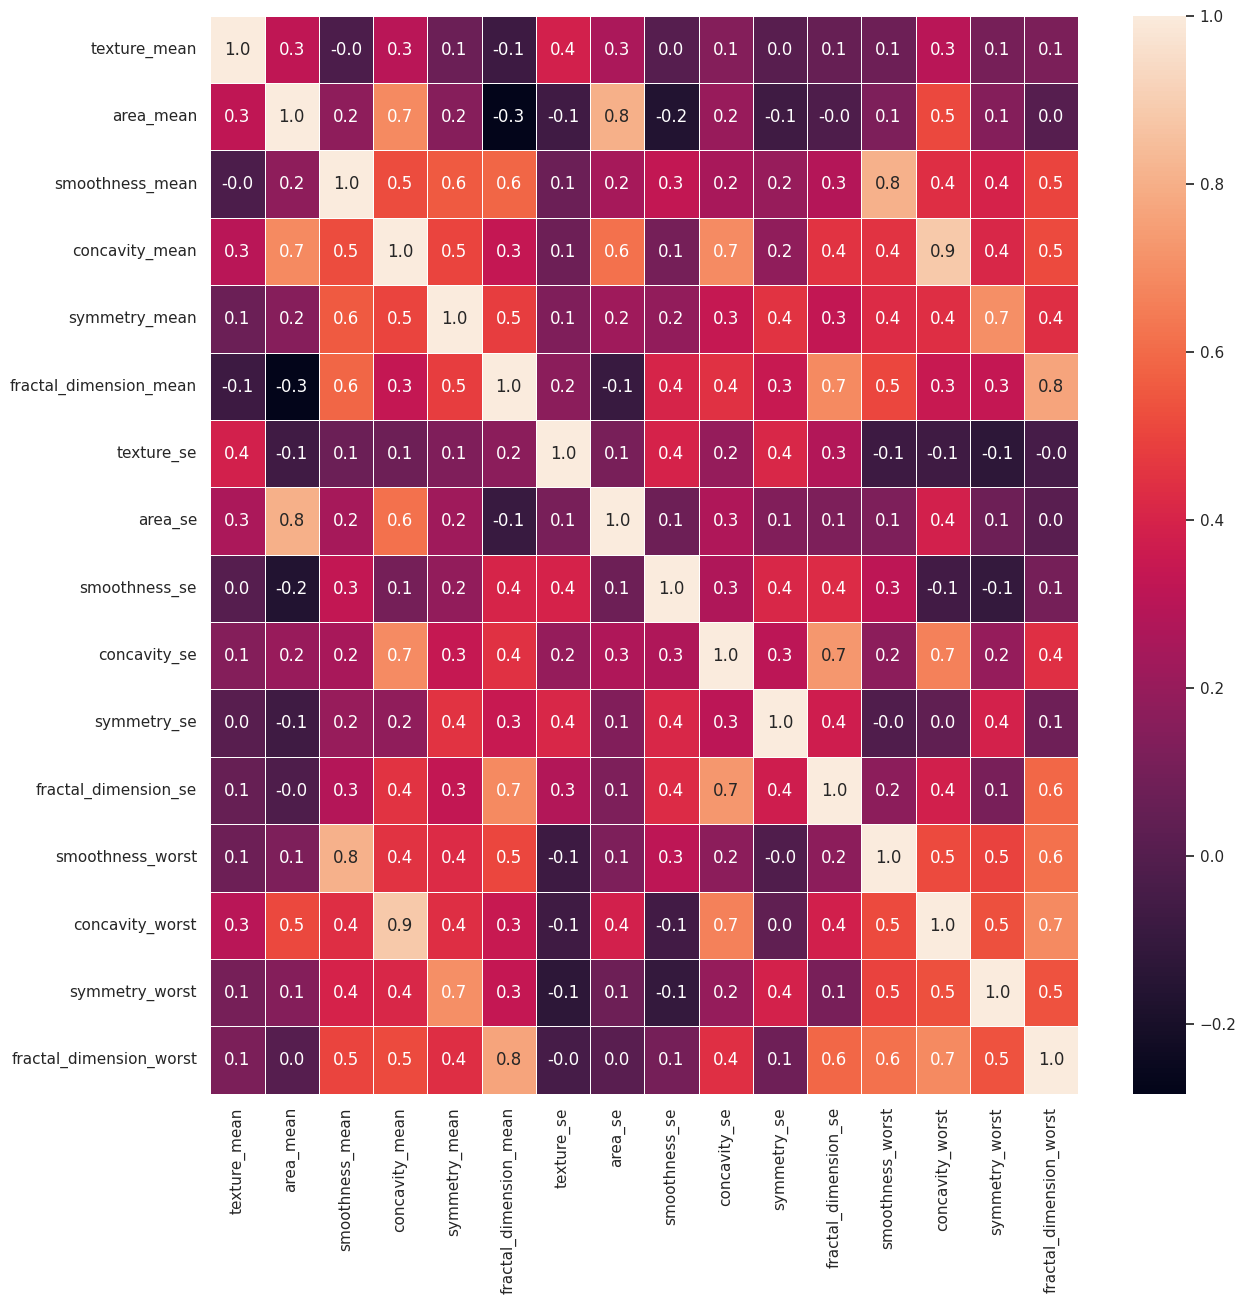

In [ ]:
#correlation map
f,ax = plt.subplots(figsize=(14, 14))
sns.heatmap(x_1.corr(), annot=True, linewidths=.5, fmt= '.1f',ax=ax)

//

## Train/Test Split

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

y_num = y.map({'M': 1, 'B': 0})   # 1 = Malignant, 0 = Benign

x_train, x_test, y_train, y_test = train_test_split(
    x, y_num, test_size=0.3, stratify=y_num, random_state=42)

print(x_train.shape, x_test.shape)

(398, 30) (171, 30)


## Baseline: Single Decision Tree

What this cell does: trains one fully grown decision tree (no depth limit) and compares train vs test accuracy. A train accuracy of about 1.0 with a lower test accuracy is the classic sign of overfitting (high variance). This is the problem bagging will fix.

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

dt = DecisionTreeClassifier(random_state=42).fit(x_train, y_train)
dt_pred = dt.predict(x_test)

print("Tree train acc:", accuracy_score(y_train, dt.predict(x_train)))
print("Tree test  acc:", accuracy_score(y_test, dt_pred))

Tree train acc: 1.0
Tree test  acc: 0.9005847953216374


## Bagging with Decision Trees

What this cell does: trains a BaggingClassifier with 100 decision trees.

bootstrap=True: each tree trains on a random sample drawn with replacement
n_estimators=100: number of trees whose votes are combined
oob_score=True: scores the model on the rows each tree did not see (a free validation estimate)
n_jobs=-1: uses all CPU cores
The final prediction is the majority vote of all trees. If you get an error about estimator, your scikit-learn is older than 1.2. Use base_estimator= instead, or run pip install -U scikit-learn

In [ ]:
from sklearn.ensemble import BaggingClassifier

bag = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    n_estimators=100,
    bootstrap=True,
    oob_score=True,
    n_jobs=-1,
    random_state=42
).fit(x_train, y_train)

bag_pred = bag.predict(x_test)

print("Bagging train acc:", accuracy_score(y_train, bag.predict(x_train)))
print("Bagging test  acc:", accuracy_score(y_test, bag_pred))
print("Bagging OOB score:", bag.oob_score_)

Bagging train acc: 1.0
Bagging test  acc: 0.9590643274853801
Bagging OOB score: 0.9447236180904522


What this cell does: a single split can be lucky or unlucky, so we measure both models on 25 different splits (5-fold CV repeated 5 times).

Mean Acc: average accuracy
Std / Variance: how much accuracy changes between splits. This is our direct measure of variance.
Expect bagging to have a similar or higher mean and a smaller std.

In [ ]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=42)

dt_cv = cross_val_score(DecisionTreeClassifier(random_state=42),
                        x, y_num, cv=cv, scoring="accuracy", n_jobs=-1)

bag_cv = cross_val_score(
    BaggingClassifier(estimator=DecisionTreeClassifier(random_state=42),
                      n_estimators=100, random_state=42),
    x, y_num, cv=cv, scoring="accuracy", n_jobs=-1)

pd.DataFrame({
    "Model": ["Decision Tree", "Bagging (100 trees)"],
    "Mean Acc": [dt_cv.mean(), bag_cv.mean()],
    "Std (variance proxy)": [dt_cv.std(), bag_cv.std()],
    "Variance": [dt_cv.var(), bag_cv.var()]
})

,Model,Mean Acc,Std (variance proxy),Variance
0,Decision Tree,0.930747,0.025258,0.000638
1,Bagging (100 trees),0.957476,0.022555,0.000509


What this cell does: boxplot of the 25 CV scores for each model. A shorter box means the scores vary less, which means lower variance. This is the visual proof of the table above.

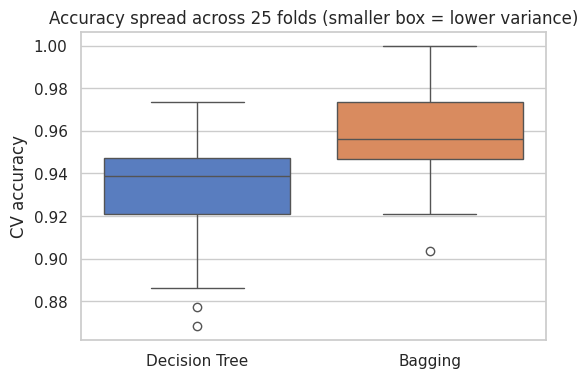

In [ ]:
plt.figure(figsize=(6, 4))
sns.boxplot(data=[dt_cv, bag_cv])
plt.xticks([0, 1], ["Decision Tree", "Bagging"])
plt.ylabel("CV accuracy")
plt.title("Accuracy spread across 25 folds (smaller box = lower variance)")
plt.show()

8. Effect of the Number of Trees
What this cell does: trains bagging with 1, 5, 10 ... 200 trees and plots CV accuracy (line) with its spread (shaded band). You should see accuracy rise quickly and then flatten, and the band narrow. With 1 tree, bagging is just a single tree on a bootstrap sample. More trees do not cause overfitting; they only cost more compute

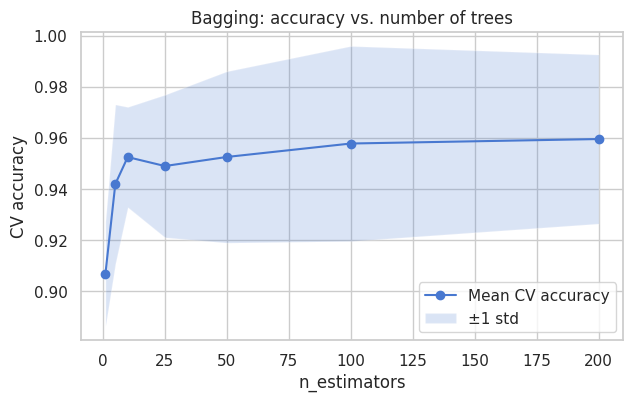

In [ ]:
ns = [1, 5, 10, 25, 50, 100, 200]
means, stds = [], []

for n in ns:
    s = cross_val_score(
        BaggingClassifier(estimator=DecisionTreeClassifier(random_state=42),
                          n_estimators=n, random_state=42, n_jobs=-1),
        x, y_num, cv=5, scoring="accuracy")
    means.append(s.mean())
    stds.append(s.std())

means, stds = np.array(means), np.array(stds)

plt.figure(figsize=(7, 4))
plt.plot(ns, means, marker="o", label="Mean CV accuracy")
plt.fill_between(ns, means - stds, means + stds, alpha=0.2, label="±1 std")
plt.xlabel("n_estimators")
plt.ylabel("CV accuracy")
plt.title("Bagging: accuracy vs. number of trees")
plt.legend()
plt.show()

9. Test-Set Evaluation
What this cell does: compares both models on the held-out test set using:

Confusion matrices: rows are actual classes, columns are predicted. Off-diagonal cells are mistakes. In this problem a false negative (malignant predicted as benign) is the costliest error.
Classification report: precision, recall and F1 per class
ROC-AUC: how well the model ranks malignant above benign (1.0 is perfect)

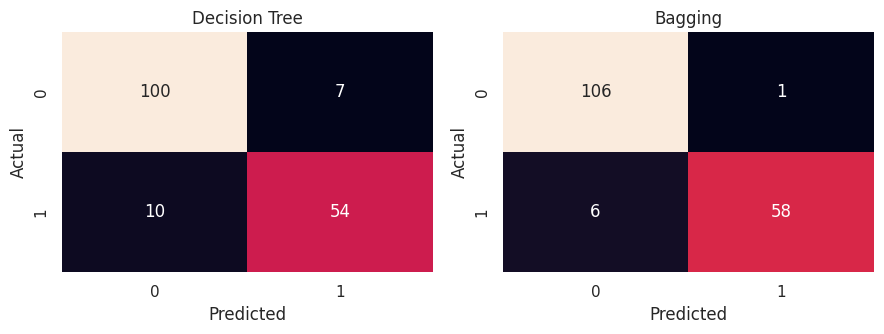

=== Decision Tree ===
              precision    recall  f1-score   support

      Benign       0.91      0.93      0.92       107
   Malignant       0.89      0.84      0.86        64

    accuracy                           0.90       171
   macro avg       0.90      0.89      0.89       171
weighted avg       0.90      0.90      0.90       171

=== Bagging ===
              precision    recall  f1-score   support

      Benign       0.95      0.99      0.97       107
   Malignant       0.98      0.91      0.94        64

    accuracy                           0.96       171
   macro avg       0.96      0.95      0.96       171
weighted avg       0.96      0.96      0.96       171

Tree AUC   : 0.8891647196261683
Bagging AUC: 0.9935017523364486


In [ ]:
from sklearn.metrics import roc_auc_score

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, pred, title in zip(axes, [dt_pred, bag_pred], ["Decision Tree", "Bagging"]):
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", ax=ax, cbar=False)
    ax.set_title(title)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

print("=== Decision Tree ===")
print(classification_report(y_test, dt_pred, target_names=["Benign", "Malignant"]))
print("=== Bagging ===")
print(classification_report(y_test, bag_pred, target_names=["Benign", "Malignant"]))

print("Tree AUC   :", roc_auc_score(y_test, dt.predict_proba(x_test)[:, 1]))
print("Bagging AUC:", roc_auc_score(y_test, bag.predict_proba(x_test)[:, 1]))

10. Feature Importance (Bagging)
What this cell does: BaggingClassifier has no built-in importance score, so we average the feature_importances_ of all 100 trees and plot the top 10. These are the features the ensemble relies on most to separate malignant from benign.

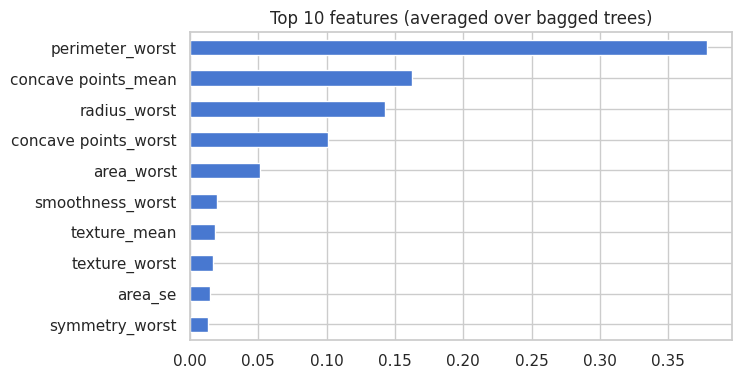

In [ ]:
imp = np.mean([t.feature_importances_ for t in bag.estimators_], axis=0)

pd.Series(imp, index=x.columns).sort_values().tail(10).plot(
    kind="barh", figsize=(7, 4))
plt.title("Top 10 features (averaged over bagged trees)")
plt.show()

## 11. Optional: Same Models on Correlation-Reduced Features
**What this cell does:** repeats the tree and bagging experiment using `x_1` (correlated features removed). The same `random_state` and `stratify` give the same rows in train and test, so `y_train` and `y_test` still match.
This shows whether removing duplicate information changes the result. Trees usually cope well with correlated features, so the difference is often small.

In [ ]:
x_train1, x_test1, _, _ = train_test_split(
    x_1, y_num, test_size=0.3, stratify=y_num, random_state=42)

dt1 = DecisionTreeClassifier(random_state=42).fit(x_train1, y_train)
bag1 = BaggingClassifier(estimator=DecisionTreeClassifier(random_state=42),
                         n_estimators=100, n_jobs=-1, random_state=42).fit(x_train1, y_train)

print("Tree    (x_1) test acc:", accuracy_score(y_test, dt1.predict(x_test1)))
print("Bagging (x_1) test acc:", accuracy_score(y_test, bag1.predict(x_test1)))

Tree    (x_1) test acc: 0.9005847953216374
Bagging (x_1) test acc: 0.9415204678362573


12. Conclusion
Fill in the blanks with the numbers from your own run.

A single decision tree reached train accuracy = ___ but test accuracy = ___, so it overfits (high variance).
Bagging with 100 trees reached test accuracy = ___ and OOB score = ___.
Over 25 CV folds, the tree's accuracy std was ___ versus ___ for bagging, so bagging clearly reduced variance.
Why it works: each tree sees a different bootstrap sample, so their errors are partly independent. Averaging the votes cancels much of that noise while keeping bias about the same.
Accuracy rises quickly with more trees and then plateaus; adding trees does not cause overfitting

**SCRIPT**

1. Introduction (about 45 sec)

Show the title cell.

“Good morning everyone. Today I’ll show how bagging with decision trees reduces model variance. The problem is that a single decision tree is very flexible, so it can memorise the training data. That gives high accuracy on training data but unstable results on new data. We’ll test this on the Breast Cancer Wisconsin dataset, where the task is to classify a tumour as malignant or benign. I’ll show the problem first, apply bagging, and then measure the improvement.”

2. Libraries and data loading (about 45 sec)

Scroll through the imports and read_csv cells.

“First I import numpy and pandas for data handling, and seaborn and matplotlib for plots. Then I load the dataset. It has 569 patient samples with 30 numeric features computed from cell nucleus images, such as radius, texture, area and concavity. The label is the diagnosis: M for malignant and B for benign.”

3. Data cleaning and understanding (about 1 min)

Show head(), the x/y split, the countplot and describe().

“I removed three columns. id is just an identifier, so it has no predictive value. Unnamed: 32 is an empty column. diagnosis is our target, so I separated it into y and kept the 30 features in x.

Next I checked the class balance: 357 benign and 212 malignant. That is moderately balanced, so accuracy is a fair metric, though I will also report recall and AUC.

describe() shows the features are on very different scales. I did not scale them, because decision trees split on thresholds and are not affected by scale.”

4. Visualization (about 1 min)

Show the violin plot, then the heatmap.

“The violin plot shows how each feature separates the two classes. Where the shapes barely overlap, like area or concavity, the feature is useful. Where they overlap, like fractal dimension, it is weak.

The heatmap shows many features are highly correlated, for example radius, perimeter and area. So I built a reduced set called x_1 with the duplicates removed. I use the full set for the main experiment and the reduced set for a comparison at the end.”

5. Train/test split (about 30 sec)

Show the split cell.

“I encoded the label as 1 for malignant and 0 for benign, then split 70% train and 30% test. I used stratify so both parts keep the same class ratio, and a fixed random seed so the results are reproducible.”

6. Baseline: single decision tree (about 1 min)

Show the output.

“This is the problem we want to solve. I trained one fully grown decision tree. Its training accuracy is 100%, but its test accuracy is only about 90%. The tree memorised the training data, including its noise. That is overfitting, and it is what high variance looks like: small changes in the training data produce a very different tree.”

7. Bagging (about 1.5 min)

Show the bagging cell and its output.

“Bagging stands for Bootstrap Aggregating. It works in three steps. First, create many random samples of the training data with replacement, which are the bootstrap samples. Second, train one decision tree on each sample, so each tree sees slightly different data and makes different mistakes. Third, combine all the trees by majority vote.

I used 100 trees. The individual errors are partly independent, so averaging cancels much of the noise. This lowers variance without increasing bias much.

The test accuracy rose from about 90% to about 96%. I also turned on the OOB score. Each tree leaves out about one third of the data, and that data gives a free validation estimate, here about 94%.”

8. Proving the variance reduction (about 1.5 min)

Show the CV table, then the boxplot.

“One test split can be lucky or unlucky, so I measured both models on 25 different splits using 5-fold cross-validation repeated 5 times.

The table shows the mean accuracy and the standard deviation, which is our direct measure of variance. Bagging has a higher mean and a clearly lower standard deviation. The boxplot shows the same thing: the bagging box is shorter and sits higher. This is the main evidence that bagging reduces variance.”

9. Effect of the number of trees (about 45 sec)

Show the line plot.

“Here I vary the number of trees from 1 to 200. Accuracy rises quickly in the first 25 to 50 trees and then flattens, and the shaded variance band narrows. So more trees never hurt accuracy, but after a point they only cost more computation. A hundred trees is a good balance.”

10. Detailed evaluation (about 1 min)

Show the confusion matrices, report and AUC.

“The confusion matrices show where each model makes mistakes. In this problem the most serious error is a false negative, a malignant tumour predicted as benign. Bagging reduces these errors compared with the single tree, and the classification report shows higher recall for the malignant class. The AUC, which measures how well the model ranks malignant above benign, also improves and is close to 1.”

11. Feature importance and reduced features (about 45 sec)

Show the importance plot and the final comparison cell.

“Bagging has no built-in importance score, so I averaged the importance values across all 100 trees. The top features are mostly area, concavity and radius related measurements, which matches what we saw in the violin plots.

Finally, I repeated the experiment on the correlation-reduced features. Bagging still beats the single tree, which shows the improvement does not depend on the feature set.”

12. Conclusion (about 45 sec)

Show the conclusion cell with your numbers filled in.

“To summarise: a single decision tree overfits, with 100% train accuracy but about 90% test accuracy. Bagging with 100 trees raised test accuracy to about 96% and reduced the spread of results across folds. It works because each tree learns from a different bootstrap sample, so their errors are partly independent and averaging their votes cancels noise. Bagging mainly reduces variance, so it helps most with unstable, high-variance models like deep decision trees. Thank you. I’m happy to take questions.”

Likely questions and short answers
Question	Answer
Why not just limit the tree depth?	That reduces variance but raises bias. Bagging keeps deep, low-bias trees and reduces variance by averaging.
How is this different from Random Forest?	Random Forest is bagging plus random feature selection at each split, which makes the trees even less correlated.
Why no feature scaling?	Trees split on thresholds, so scaling does not change the splits.
What is OOB?	Out-of-bag samples are the rows a tree did not see in its bootstrap sample. They act as a built-in validation set.
Does bagging reduce bias?	Not much. It mainly reduces variance.
Why use cross-validation?	One split can be lucky or unlucky. Repeated CV gives a more reliable estimate and lets us measure the spread.

Before presenting, run the notebook once from top to bottom and update every number in the script (and the conclusion cell) with your own results. I can also turn this into a slide deck or a Word document if you want one.